# Iris Flower Classification
Supervised classification with **Logistic Regression** and **Decision Tree** (Scikit-learn).

## 1. Import libraries

In [1]:
%pip install -q seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_theme(style="whitegrid")

## 2. Load and inspect the data

In [3]:
df = pd.read_csv("iris.csv")
display(df.head())
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:\n", df["species"].value_counts())
df.describe()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Shape: (150, 5)

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Class counts:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Exploratory analysis using pairplot


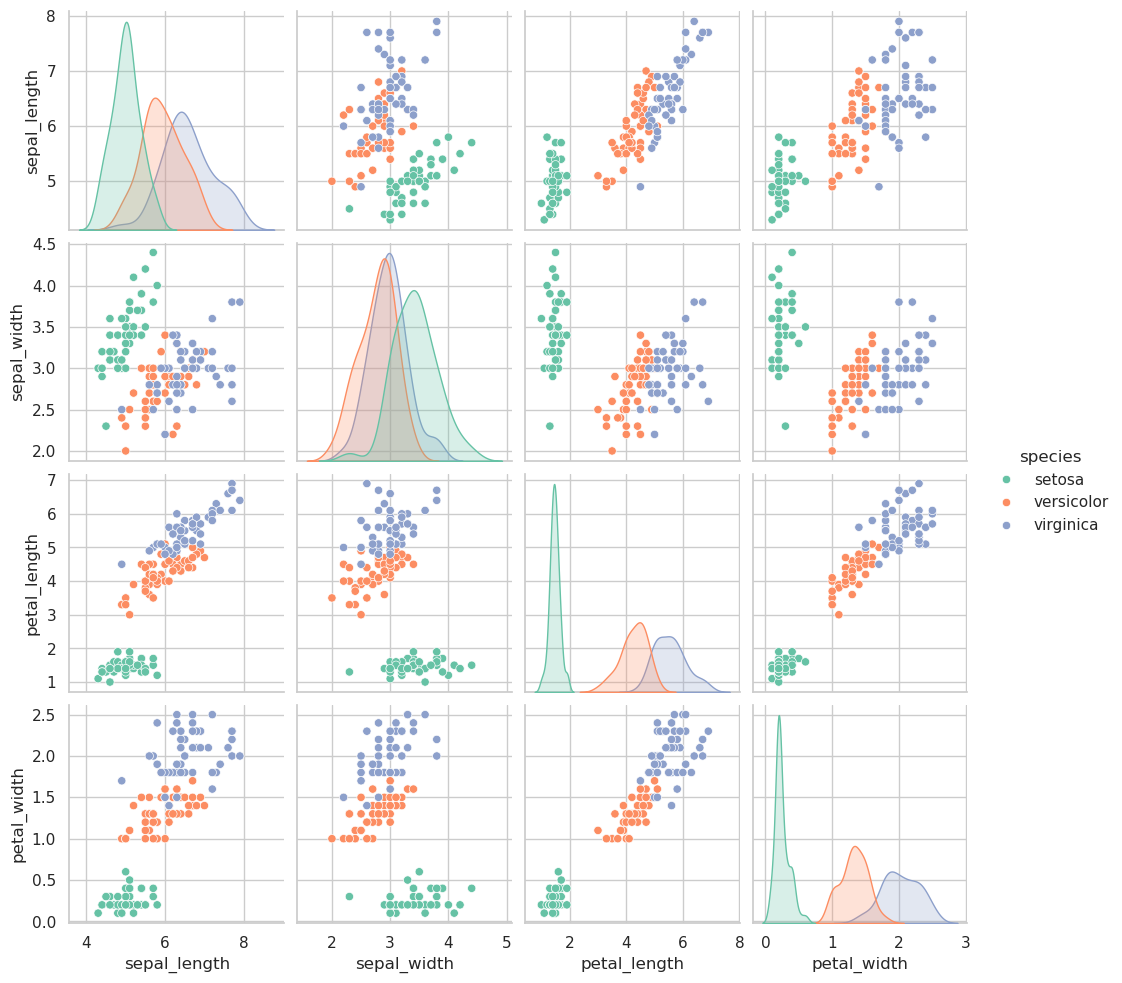

In [4]:
sns.pairplot(df, hue="species", palette="Set2")
plt.show()

## 4. Features, target, and 80/20 split

In [5]:
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (120, 4) | Test: (30, 4)


## 5. Feature scaling using StandardScaler


In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Train the models

In [7]:
log_reg = LogisticRegression(max_iter=200, random_state=42)
tree = DecisionTreeClassifier(random_state=42)

log_reg.fit(X_train_scaled, y_train)
tree.fit(X_train_scaled, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

## 7. Evaluate: accuracy, precision, recall, F1

In [8]:
pred_lr = log_reg.predict(X_test_scaled)
pred_tree = tree.predict(X_test_scaled)

print("Logistic Regression\n", classification_report(y_test, pred_lr))
print("Decision Tree\n", classification_report(y_test, pred_tree))

def score(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "F1-score": f1_score(y_true, y_pred, average="macro"),
    }

results = pd.DataFrame({
    "Logistic Regression": score(y_test, pred_lr),
    "Decision Tree": score(y_test, pred_tree),
}).T.round(3)
results

Logistic Regression
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


## 8. Confusion matrices

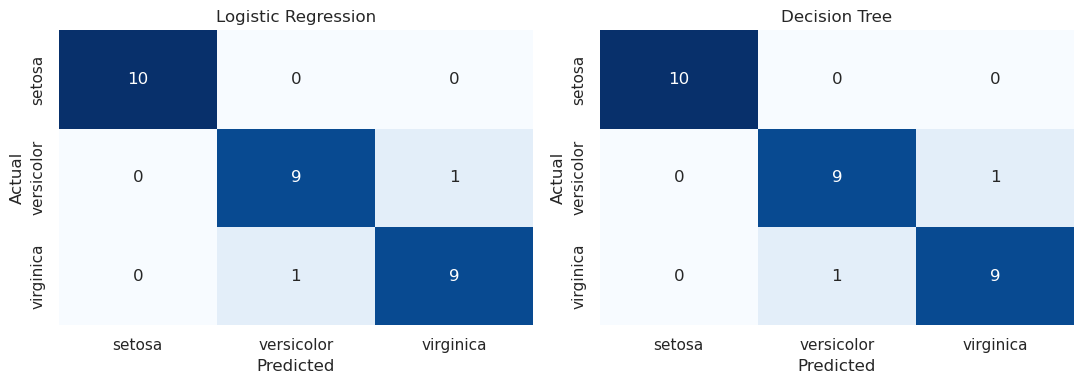

In [9]:
labels = ["setosa", "versicolor", "virginica"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, preds, name in zip(axes, [pred_lr, pred_tree], ["Logistic Regression", "Decision Tree"]):
    cm = confusion_matrix(y_test, preds, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

## 9. Decision boundaries (petal length vs petal width)
A 2D plot can only show two features, so the models are retrained on just these two.

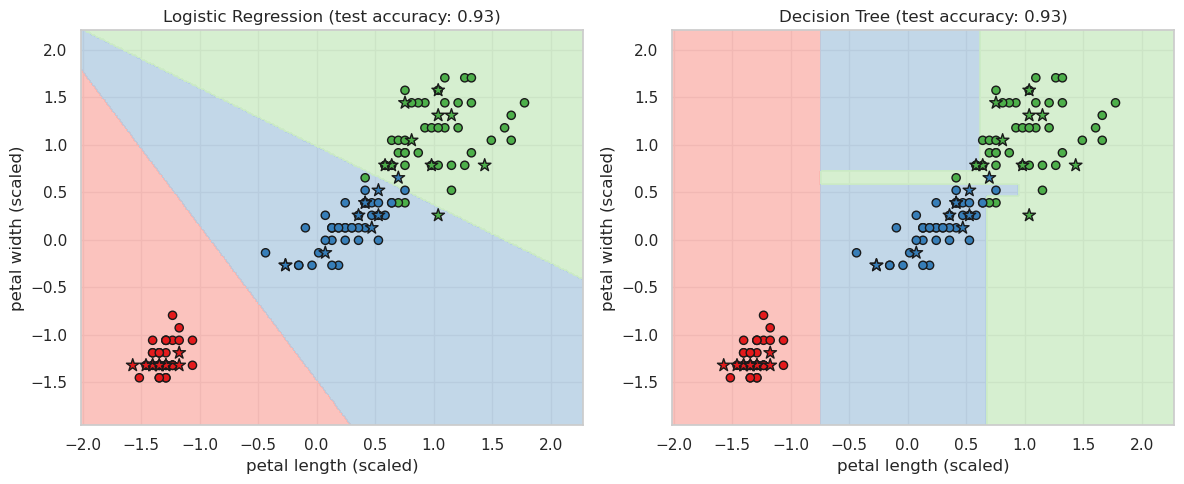

red = setosa, blue = versicolor, green = virginica | circles = train, stars = test


In [10]:
features = ["petal_length", "petal_width"]
sc2 = StandardScaler()
X2_train = sc2.fit_transform(X_train[features])
X2_test = sc2.transform(X_test[features])

to_num = {name: i for i, name in enumerate(labels)}
y2_train = y_train.map(to_num).values
y2_test = y_test.map(to_num).values

cmap_bg = ListedColormap(["#fbb4ae", "#b3cde3", "#ccebc5"])
cmap_pts = ListedColormap(["#e41a1c", "#377eb8", "#4daf4a"])

x_min, x_max = X2_train[:, 0].min() - 0.5, X2_train[:, 0].max() + 0.5
y_min, y_max = X2_train[:, 1].min() - 0.5, X2_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

models = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X2_train, y2_train)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.8)
    ax.scatter(X2_train[:, 0], X2_train[:, 1], c=y2_train, cmap=cmap_pts, edgecolor="k", s=35)
    ax.scatter(X2_test[:, 0], X2_test[:, 1], c=y2_test, cmap=cmap_pts, edgecolor="k", s=90, marker="*")
    ax.set_title(f"{name} (test accuracy: {model.score(X2_test, y2_test):.2f})")
    ax.set_xlabel("petal length (scaled)")
    ax.set_ylabel("petal width (scaled)")

plt.tight_layout()
plt.show()
print("red = setosa, blue = versicolor, green = virginica | circles = train, stars = test")

## 10. Conclusion

In this project, I built a classification pipeline on the Iris dataset (150 flowers, 3 species, 4 measurements). I checked the data for missing values and duplicates, split it 80/20, scaled the features with StandardScaler (fitted on the training data only to avoid data leakage), and trained Logistic Regression and a Decision Tree.

**Results:** Both models reached **93.3% accuracy**, with precision, recall, and F1-score of 0.933 each. They tied, and each classified 28 of the 30 test flowers correctly.

**Observations:**
- Setosa was classified perfectly by both models. The pairplot shows it sits far away from the other two species.
- All the errors were between versicolor and virginica, whose petal measurements overlap.
- Petal length and petal width were the most useful features for separating the species, as the decision boundary plots show.
- The Decision Tree drew box-shaped regions (it works by asking yes/no questions), while Logistic Regression drew smoother, straighter borders.

